# Prioritized Experience Replay

**Paper:** [Schaul et al., 2016 — Prioritized Experience Replay](https://arxiv.org/abs/1511.05952)

This notebook implements Prioritized Experience Replay (PER) from scratch in NumPy: the sum-tree data structure, proportional prioritization and importance-sampling weights. It compares a DQN agent with prioritized replay against one with uniform replay on a small gridworld. The Summary at the end says what this run found.


## 1. Setup & Imports

In [1]:
import os
# One BLAS thread, so NumPy results do not depend on the machine's core count
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')

import atexit
import shutil
import numpy as np
import random
import math
from collections import deque
import matplotlib.pyplot as plt
import matplotlib
from matplotlib_inline.backend_inline import set_matplotlib_formats
matplotlib.rcParams['figure.figsize'] = (12, 5)

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print('Imports ready')


Imports ready


## 2. Sum-Tree Data Structure

The sum-tree is a binary tree where each leaf holds a priority and each internal node holds the sum of its children. This allows O(log N) sampling and priority updates.


In [2]:
class SumTree:
    """Binary tree where leaves hold priorities and internal nodes hold sums."""
    def __init__(self, capacity):
        self.capacity = capacity
        self.tree = np.zeros(2 * capacity - 1, dtype=np.float64)
        self.data = [None] * capacity
        self.write_ptr = 0
        self.n_entries = 0

    def _propagate(self, idx):
        parent = (idx - 1) // 2
        while True:
            self.tree[parent] = self.tree[2 * parent + 1] + self.tree[2 * parent + 2]
            if parent == 0:
                break
            parent = (parent - 1) // 2

    def _retrieve(self, idx, value):
        leaf = idx
        while leaf < self.capacity - 1:
            left = 2 * leaf + 1
            right = left + 1
            if value <= self.tree[left]:
                leaf = left
            else:
                value -= self.tree[left]
                leaf = right
        return leaf

    def total(self):
        return float(self.tree[0])

    def add(self, priority, data):
        leaf_idx = self.write_ptr + self.capacity - 1
        self.data[self.write_ptr] = data
        self.update(leaf_idx, priority)
        self.write_ptr = (self.write_ptr + 1) % self.capacity
        if self.n_entries < self.capacity:
            self.n_entries += 1

    def update(self, leaf_idx, priority):
        self.tree[leaf_idx] = priority
        self._propagate(leaf_idx)

    def get(self, value):
        leaf_idx = self._retrieve(0, value)
        data_idx = leaf_idx - self.capacity + 1
        return leaf_idx, float(self.tree[leaf_idx]), self.data[data_idx]

# Quick test
tree = SumTree(8)
for i in range(8):
    tree.add(float(i + 1), f'transition_{i}')
print(f'Total priority: {tree.total()}')
print(f'Sample at value=1: {tree.get(1.0)}')
print(f'Sample at value=35: {tree.get(35.0)}')

Total priority: 36.0
Sample at value=1: (7, 1.0, 'transition_0')
Sample at value=35: (14, 8.0, 'transition_7')


## 3. Prioritized Replay Buffer

In [3]:
class PrioritizedReplayBuffer:
    def __init__(self, capacity, alpha=0.6, beta=0.4, beta_end=1.0, beta_anneal_steps=10000, epsilon=1e-6):
        self.tree = SumTree(capacity)
        self.capacity = capacity
        self.alpha = alpha
        self.beta = beta
        self.beta_start = beta
        self.beta_end = beta_end
        self.beta_anneal_steps = beta_anneal_steps
        self.epsilon = epsilon
        self.max_priority = 1.0

    def __len__(self):
        return self.tree.n_entries

    def add(self, state, action, reward, next_state, done):
        transition = (state.copy(), action, reward, next_state.copy(), done)
        priority = (self.max_priority + self.epsilon) ** self.alpha
        self.tree.add(priority, transition)

    def sample(self, batch_size):
        indices = []
        priorities = []
        transitions = []
        segment = self.tree.total() / batch_size
        self.beta = min(self.beta_end, self.beta + (self.beta_end - self.beta_start) / self.beta_anneal_steps)

        for i in range(batch_size):
            a = segment * i
            b = segment * (i + 1)
            s = random.uniform(a, b)
            leaf_idx, priority, data = self.tree.get(s)
            if data is None:
                data_idx = random.randint(0, self.tree.n_entries - 1)
                leaf_idx = data_idx + self.tree.capacity - 1
                priority = float(self.tree.tree[leaf_idx])
                data = self.tree.data[data_idx]
                if data is None:
                    continue
            indices.append(leaf_idx)
            priorities.append(max(priority, 1e-8))
            transitions.append(data)

        if len(transitions) == 0:
            return None, None, None

        sampling_probs = np.array(priorities) / max(self.tree.total(), 1e-8)
        weights = (len(self) * sampling_probs) ** (-self.beta)
        weights = np.nan_to_num(weights, nan=1.0, posinf=1.0, neginf=1.0)
        max_w = weights.max()
        if max_w > 0:
            weights /= max_w

        states = np.array([t[0] for t in transitions])
        actions = np.array([t[1] for t in transitions])
        rewards = np.array([t[2] for t in transitions])
        next_states = np.array([t[3] for t in transitions])
        dones = np.array([t[4] for t in transitions])

        return (states, actions, rewards, next_states, dones), np.array(indices), weights.astype(np.float32)

    def update_priorities(self, indices, td_errors):
        for idx, td_error in zip(indices, td_errors):
            priority = (abs(float(td_error)) + self.epsilon) ** self.alpha
            priority = min(priority, 1e4)
            self.tree.update(idx, priority)
            if priority > self.max_priority:
                self.max_priority = priority

print('PrioritizedReplayBuffer defined')

PrioritizedReplayBuffer defined


## 4. Uniform Replay Buffer (Baseline)

In [4]:
class UniformReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def __len__(self):
        return len(self.buffer)

    def add(self, state, action, reward, next_state, done):
        self.buffer.append((state.copy(), action, reward, next_state.copy(), done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states = np.array([t[0] for t in batch])
        actions = np.array([t[1] for t in batch])
        rewards = np.array([t[2] for t in batch])
        next_states = np.array([t[3] for t in batch])
        dones = np.array([t[4] for t in batch])
        weights = np.ones(batch_size, dtype=np.float32)
        return (states, actions, rewards, next_states, dones), None, weights

    def update_priorities(self, indices, td_errors):
        pass

print('UniformReplayBuffer defined')

UniformReplayBuffer defined


## 5. Toy Environment: Simple Gridworld

A 1D gridworld with a goal at the far end. The agent starts at position 0 and must reach position N-1.

- State: one-hot encoded position (dimension = grid size, 6 here)
- Actions: left (0) or right (1)
- Reward: +1 at the goal, -0.01 per other step
- The episode ends at the goal or after 30 steps


In [5]:
class SimpleGridworld:
    def __init__(self, size=6, max_steps=30):
        self.size = size
        self.max_steps = max_steps
        self.reset()

    def reset(self):
        self.pos = 0
        self.steps = 0
        # One-hot encoding for better network input
        s = np.zeros(self.size, dtype=np.float32)
        s[self.pos] = 1.0
        return s

    def step(self, action):
        self.steps += 1
        if action == 1:  # right
            self.pos = min(self.pos + 1, self.size - 1)
        else:  # left
            self.pos = max(self.pos - 1, 0)

        done = (self.pos == self.size - 1) or (self.steps >= self.max_steps)
        if self.pos == self.size - 1 and self.steps < self.max_steps:
            reward = 1.0
        else:
            reward = -0.01

        s = np.zeros(self.size, dtype=np.float32)
        s[self.pos] = 1.0
        return s, reward, done

    @property
    def state_dim(self):
        return self.size

    @property
    def action_dim(self):
        return 2

# Test
env = SimpleGridworld(size=6)
s = env.reset()
print(f'Initial state: {s}')
s, r, d = env.step(1)
print(f'After right: state={s}, reward={r}, done={d}')

Initial state: [1. 0. 0. 0. 0. 0.]
After right: state=[0. 1. 0. 0. 0. 0.], reward=-0.01, done=False


## 6. Q-Network (Small MLP, from scratch in numpy)

In [6]:
class QNetwork:
    def __init__(self, state_dim, action_dim, hidden=64, lr=0.01):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.lr = lr
        scale1 = np.sqrt(2.0 / state_dim)
        scale2 = np.sqrt(2.0 / hidden)
        scale3 = np.sqrt(2.0 / hidden)
        self.W1 = np.random.randn(state_dim, hidden) * scale1
        self.b1 = np.zeros(hidden)
        self.W2 = np.random.randn(hidden, hidden) * scale2
        self.b2 = np.zeros(hidden)
        self.W3 = np.random.randn(hidden, action_dim) * scale3
        self.b3 = np.zeros(action_dim)

    def forward(self, states):
        self.h1 = np.maximum(0, states @ self.W1 + self.b1)
        self.h2 = np.maximum(0, self.h1 @ self.W2 + self.b2)
        self.q = self.h2 @ self.W3 + self.b3
        self.states = states
        return self.q

    def backward(self, td_errors, actions, weights):
        batch_size = len(actions)
        # Loss is w * (q - target)^2 = w * td^2 with td = target - q, so dLoss/dq = -2 * w * td
        dQ = -2.0 * weights * td_errors  # (batch, 1)
        action_onehot = np.zeros((batch_size, self.action_dim))
        action_onehot[np.arange(batch_size), actions] = 1.0
        dQ = dQ * action_onehot

        dW3 = self.h2.T @ dQ / batch_size
        db3 = dQ.mean(axis=0)
        dh2 = dQ @ self.W3.T
        dh2[self.h2 <= 0] = 0

        dW2 = self.h1.T @ dh2 / batch_size
        db2 = dh2.mean(axis=0)
        dh1 = dh2 @ self.W2.T
        dh1[self.h1 <= 0] = 0

        dW1 = self.states.T @ dh1 / batch_size
        db1 = dh1.mean(axis=0)

        for g in [dW1, db1, dW2, db2, dW3, db3]:
            np.clip(g, -10, 10, out=g)

        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W3 -= self.lr * dW3
        self.b3 -= self.lr * db3

        for w in [self.W1, self.W2, self.W3]:
            np.clip(w, -100, 100, out=w)

    def copy_from(self, other):
        self.W1 = other.W1.copy()
        self.b1 = other.b1.copy()
        self.W2 = other.W2.copy()
        self.b2 = other.b2.copy()
        self.W3 = other.W3.copy()
        self.b3 = other.b3.copy()

print('QNetwork defined')

QNetwork defined


## 7. DQN Agent with Configurable Replay Buffer

In [7]:
class DQNAgent:
    def __init__(self, state_dim, action_dim, lr=0.01, gamma=0.95,
                 epsilon_start=1.0, epsilon_end=0.1, epsilon_decay=0.998,
                 target_update_freq=100, buffer_type='uniform', buffer_size=5000,
                 batch_size=32, alpha=0.6, beta=0.4, beta_anneal_steps=5000):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.target_update_freq = target_update_freq
        self.batch_size = batch_size
        self.train_steps = 0

        self.online_net = QNetwork(state_dim, action_dim, lr=lr)
        self.target_net = QNetwork(state_dim, action_dim, lr=lr)
        self.target_net.copy_from(self.online_net)

        if buffer_type == 'prioritized':
            self.buffer = PrioritizedReplayBuffer(buffer_size, alpha=alpha, beta=beta,
                                                   beta_anneal_steps=beta_anneal_steps)
        else:
            self.buffer = UniformReplayBuffer(buffer_size)

    def act(self, state, training=True):
        if training and random.random() < self.epsilon:
            return random.randrange(self.action_dim)
        q = self.online_net.forward(state.reshape(1, -1))
        return int(np.argmax(q[0]))

    def learn(self):
        if len(self.buffer) < self.batch_size:
            return None

        result = self.buffer.sample(self.batch_size)
        if result[0] is None:
            return None
        (states, actions, rewards, next_states, dones), indices, weights = result

        q_values = self.online_net.forward(states)
        q_sa = q_values[np.arange(len(actions)), actions]

        next_q = self.target_net.forward(next_states)
        next_q_max = next_q.max(axis=1)
        targets = rewards + self.gamma * next_q_max * (1 - dones)

        td_errors = targets - q_sa
        td_errors = np.nan_to_num(td_errors, nan=0.0, posinf=0.0, neginf=0.0)
        td_errors = np.clip(td_errors, -100, 100)

        self.online_net.backward(td_errors.reshape(-1, 1), actions, weights.reshape(-1, 1))

        if indices is not None:
            self.buffer.update_priorities(indices, td_errors)

        self.epsilon = max(self.epsilon_end, self.epsilon * self.epsilon_decay)

        self.train_steps += 1
        if self.train_steps % self.target_update_freq == 0:
            self.target_net.copy_from(self.online_net)

        return float(np.mean(np.abs(td_errors)))

print('DQNAgent defined')

DQNAgent defined


## 8. Training Loop: Uniform vs Prioritized Replay

In [8]:
def train_agent(buffer_type='uniform', num_episodes=500, env_size=6, seed=0):
    random.seed(seed)
    np.random.seed(seed)

    env = SimpleGridworld(size=env_size, max_steps=30)
    agent = DQNAgent(
        state_dim=env.state_dim,
        action_dim=env.action_dim,
        lr=0.01,
        gamma=0.95,
        epsilon_start=1.0,
        epsilon_end=0.1,
        epsilon_decay=0.998,
        target_update_freq=100,
        buffer_type=buffer_type,
        buffer_size=5000,
        batch_size=32,
        alpha=0.6,
        beta=0.4,
        beta_anneal_steps=5000
    )

    episode_rewards = []
    td_error_history = []
    beta_history = []
    successes = 0

    for ep in range(num_episodes):
        state = env.reset()
        total_reward = 0
        done = False

        while not done:
            action = agent.act(state)
            next_state, reward, done = env.step(action)
            agent.buffer.add(state, action, reward, next_state, done)
            mean_td = agent.learn()
            state = next_state
            total_reward += reward

        if reward == 1.0:
            successes += 1
        episode_rewards.append(total_reward)
        if mean_td is not None:
            td_error_history.append(mean_td)
        if hasattr(agent.buffer, 'beta'):
            beta_history.append(agent.buffer.beta)

        if (ep + 1) % 100 == 0:
            avg = np.mean(episode_rewards[-100:])
            print(f'  [{buffer_type:>11}] Ep {ep+1:>3} | Avg rwd (100): {avg:.3f} | Successes: {successes} | Eps: {agent.epsilon:.3f}')

    return {
        'rewards': episode_rewards,
        'td_errors': td_error_history,
        'beta': beta_history,
        'agent': agent,
        'successes': successes,
    }

print('Training function defined')

Training function defined


In [9]:
print('Training DQN with Uniform Replay...')
uniform_results = train_agent(buffer_type='uniform', num_episodes=500, seed=SEED)
print()
print('Training DQN with Prioritized Replay...')
per_results = train_agent(buffer_type='prioritized', num_episodes=500, seed=SEED)

Training DQN with Uniform Replay...


  [    uniform] Ep 100 | Avg rwd (100): 0.636 | Successes: 76 | Eps: 0.100


  [    uniform] Ep 200 | Avg rwd (100): 0.956 | Successes: 176 | Eps: 0.100


  [    uniform] Ep 300 | Avg rwd (100): 0.954 | Successes: 276 | Eps: 0.100


  [    uniform] Ep 400 | Avg rwd (100): 0.956 | Successes: 376 | Eps: 0.100


  [    uniform] Ep 500 | Avg rwd (100): 0.956 | Successes: 476 | Eps: 0.100

Training DQN with Prioritized Replay...


  [prioritized] Ep 100 | Avg rwd (100): 0.674 | Successes: 79 | Eps: 0.100


  [prioritized] Ep 200 | Avg rwd (100): 0.957 | Successes: 179 | Eps: 0.100


  [prioritized] Ep 300 | Avg rwd (100): 0.954 | Successes: 279 | Eps: 0.100


  [prioritized] Ep 400 | Avg rwd (100): 0.955 | Successes: 379 | Eps: 0.100


  [prioritized] Ep 500 | Avg rwd (100): 0.955 | Successes: 479 | Eps: 0.100


## 9. Visualization: Reward Curves and TD Error Analysis

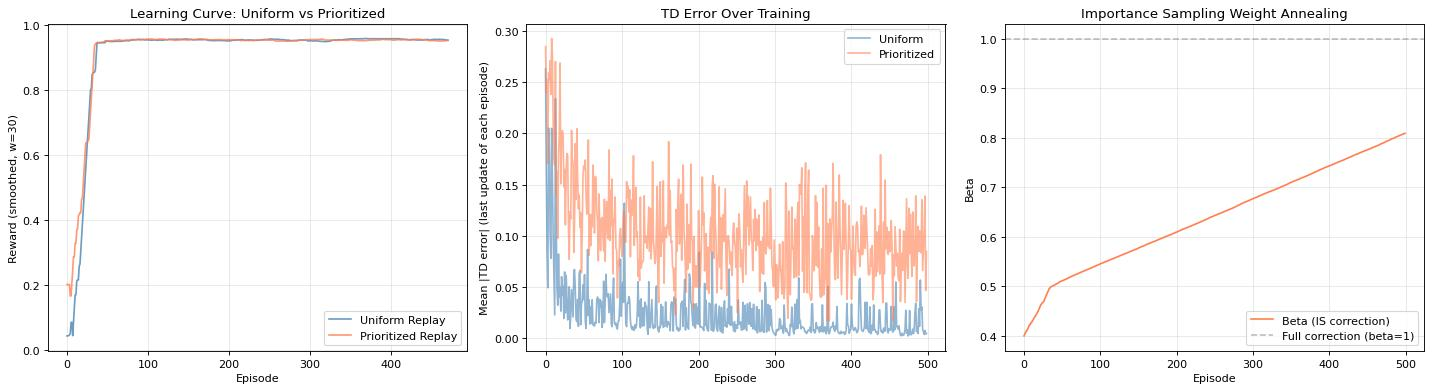

Plot saved as per_comparison.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
window = 30
u_rewards = uniform_results['rewards']
p_rewards = per_results['rewards']
if len(u_rewards) >= window:
    u_smoothed = np.convolve(u_rewards, np.ones(window)/window, mode='valid')
    p_smoothed = np.convolve(p_rewards, np.ones(window)/window, mode='valid')
    ax.plot(u_smoothed, label='Uniform Replay', color='steelblue', alpha=0.8)
    ax.plot(p_smoothed, label='Prioritized Replay', color='coral', alpha=0.8)
else:
    ax.plot(u_rewards, label='Uniform', color='steelblue')
    ax.plot(p_rewards, label='Prioritized', color='coral')
ax.set_xlabel('Episode')
ax.set_ylabel(f'Reward (smoothed, w={window})')
ax.set_title('Learning Curve: Uniform vs Prioritized')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(uniform_results['td_errors'], label='Uniform', color='steelblue', alpha=0.6)
ax.plot(per_results['td_errors'], label='Prioritized', color='coral', alpha=0.6)
ax.set_xlabel('Episode')
ax.set_ylabel('Mean |TD error| (last update of each episode)')
ax.set_title('TD Error Over Training')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[2]
if per_results['beta']:
    ax.plot(per_results['beta'], color='coral', label='Beta (IS correction)')
    ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5, label='Full correction (beta=1)')
ax.set_xlabel('Episode')
ax.set_ylabel('Beta')
ax.set_title('Importance Sampling Weight Annealing')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('per_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved as per_comparison.png')

## 10. Sample Efficiency Comparison

In [11]:
threshold = 0.5
window = 30

def episodes_to_threshold(rewards, threshold, window):
    for i in range(len(rewards) - window + 1):
        if np.mean(rewards[i:i+window]) >= threshold:
            return i + window
    return len(rewards)

uniform_eps = episodes_to_threshold(uniform_results['rewards'], threshold, window)
per_eps = episodes_to_threshold(per_results['rewards'], threshold, window)

print(f'Episodes to reach avg reward >= {threshold} (window={window}):')
print(f'  Uniform Replay:     {uniform_eps} episodes')
print(f'  Prioritized Replay: {per_eps} episodes')
if uniform_eps > 0 and per_eps > 0 and per_eps < uniform_eps:
    speedup = uniform_eps / per_eps
    print(f'  Speedup: {speedup:.2f}x')
elif per_eps == len(per_results['rewards']):
    print('  (Prioritized replay did not reach threshold)')
elif uniform_eps == len(uniform_results['rewards']):
    print('  (Uniform replay did not reach threshold)')

print()
print(f'Total successes (goal reached):')
print(f'  Uniform:     {uniform_results["successes"]}')
print(f'  Prioritized: {per_results["successes"]}')
print()
print(f'Final avg reward (last 50 episodes):')
print(f'  Uniform:     {np.mean(uniform_results["rewards"][-50:]):.3f}')
print(f'  Prioritized: {np.mean(per_results["rewards"][-50:]):.3f}')

Episodes to reach avg reward >= 0.5 (window=30):
  Uniform Replay:     52 episodes
  Prioritized Replay: 50 episodes
  Speedup: 1.04x

Total successes (goal reached):
  Uniform:     476
  Prioritized: 479

Final avg reward (last 50 episodes):
  Uniform:     0.955
  Prioritized: 0.954


## 11. Buffer Priority Distribution

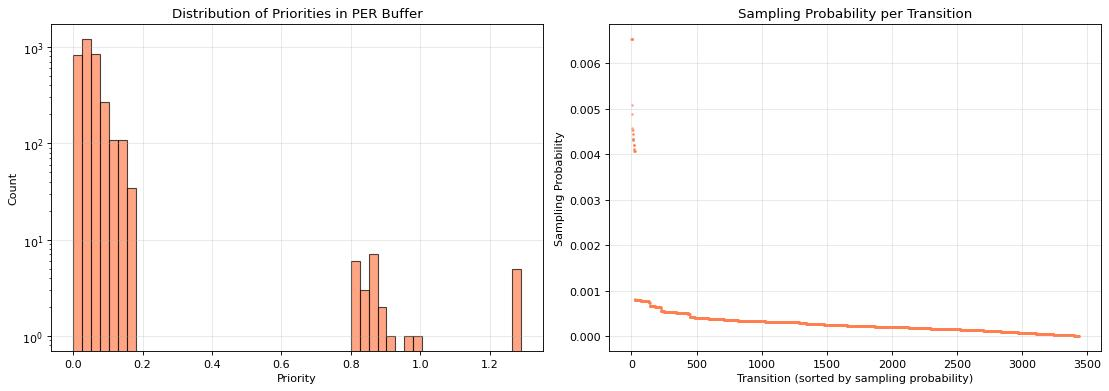

Buffer has 3437 transitions
Max priority: 1.289442
Min priority: 0.000334
Total priority sum: 196.8751


In [12]:
per_buffer = per_results['agent'].buffer

if hasattr(per_buffer, 'tree') and len(per_buffer) > 0:
    tree = per_buffer.tree
    leaf_start = tree.capacity - 1
    n = tree.n_entries
    priorities = tree.tree[leaf_start:leaf_start + n]
    priorities = priorities[priorities > 0]
    
    if len(priorities) > 0:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        ax = axes[0]
        ax.hist(priorities, bins=50, color='coral', alpha=0.7, edgecolor='black')
        ax.set_xlabel('Priority')
        ax.set_ylabel('Count')
        ax.set_title('Distribution of Priorities in PER Buffer')
        ax.set_yscale('log')
        ax.grid(True, alpha=0.3)
        
        ax = axes[1]
        total = tree.total()
        probs = priorities / total
        ax.scatter(range(len(probs)), sorted(probs, reverse=True), s=2, color='coral', alpha=0.5)
        ax.set_xlabel('Transition (sorted by sampling probability)')
        ax.set_ylabel('Sampling Probability')
        ax.set_title('Sampling Probability per Transition')
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('per_priority_distribution.png', dpi=150, bbox_inches='tight')
        plt.show()
        print(f'Buffer has {len(per_buffer)} transitions')
        print(f'Max priority: {priorities.max():.6f}')
        print(f'Min priority: {priorities.min():.6f}')
        print(f'Total priority sum: {total:.4f}')
    else:
        print('No non-zero priorities found in buffer')
else:
    print('PER buffer is empty or not available')

## 12. Summary

### What the run above shows

Both agents are the same NumPy DQN (two hidden layers of 64, learning rate 0.01, γ = 0.95, buffer of 5,000, batch of 32, 500 episodes); only the replay buffer differs. Prioritized replay uses α = 0.6 with β annealed from 0.4.

- **Both agents learn the task, and prioritized replay gives no clear gain here.** The 30-episode average reward first reached 0.5 after **52** episodes with uniform replay and **50** with prioritized replay (1.04×). Over 500 episodes they reached the goal **476** and **479** times, and the final 50-episode averages were **0.955** and **0.954**.
- **TD errors stay small.** The mean |TD error| of the sampled batches falls from about 0.2–0.3 to below 0.15. It is higher for prioritized replay throughout, as expected, because it deliberately samples the transitions with the largest errors.
- **Priorities spread out.** At the end, the prioritized buffer held 3,437 transitions with priorities from 0.0003 to 1.29, so some transitions were far more likely to be replayed than others.
- **Why no gain:** the 6-cell gridworld is easy (the goal is always to the right), and both agents solve it within about 50 episodes. The paper's gains come from Atari, where some rare transitions matter much more than others.
- **A bug fix in this version:** earlier versions of this notebook had the gradient sign reversed in `QNetwork.backward`, so the Q-values diverged and the TD errors sat at their clip value of 100. The numbers above come from the corrected code.

**Paper results (Atari):** added to DQN, prioritized replay improved the score on 41 of 49 games. With Double DQN, the median normalized score went from 111% to 128% with proportional prioritization (113% with rank-based).
